In [1]:
%pip install -q otter-grader


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


# Case Study 13: Can Thirteen Lab Measurements Tell Wines Apart?

**DS701 — Session 16 (Wed Oct 28, 2026) — Section A1**

[![](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tools4ds/DS701-Materials-FA26/blob/main/class_activity_notebooks/13-InClass-Exercise-Dimensionality-Reduction-A1/13-InClass-Exercise-Dimensionality-Reduction-A1.ipynb)

**Time: ~35 minutes.** Work in groups of 2-3.

Parts marked **(autograded)** are submitted to Gradescope; open-ended parts are graded
for participation. You may use AI assistance, but you must be able to explain and
justify every part of your solution when asked — staff will circulate and ask.

**Plan**

| Part | The lab's question | Method | Grading | Time |
|---|---|---|---|---|
| 1 | How many of our 13 measurements actually carry the signal? | Standardize, run PCA, choose $d$ from explained variance | autograded | ~12 min |
| 2 | If we keep $d$ of them, how much do we lose — and is this the SVD our engineers already know? | Reconstruction error; PCA *is* the SVD from last lecture | autograded | ~13 min |
| — | Report out: what you would tell the lab | team memo, then pair-share | participation | ~10 min |

Dependencies: `numpy`, `pandas`, `matplotlib`, `scikit-learn`.


## Case Study Setup

You are a data scientist consulting for an **analytical-chemistry lab** that serves
New England wine importers. For every lot an importer brings in, the lab runs a panel
of **13 chemical assays** — alcohol, malic acid, ash, flavanoids, colour intensity,
proline and so on — and the importer pays per measurement. Two things have landed on
the lab director's desk at once. First, a cost question: *do all 13 measurements carry
independent information, or is the panel largely redundant — and if we kept fewer
numbers per lot, how much would we lose?* Second, a sales deck from an instrument
vendor with a t-SNE plot of wines that, the vendor says, "proves" their panel separates
wines by producer. The director wants to know what that plot does and does not prove
before quoting it to importers.

The lab's own assay records are not available to you yet, so you build a prototype on
the public **UCI Wine** dataset: a chemical analysis of wines grown in one region of
Italy by three different cultivators, distributed through the UCI Machine Learning
Repository. It ships with `scikit-learn`, so nothing is downloaded:

- **178 wines**, 13 chemical measurements each — the same kind of panel the lab runs.
- **3 cultivars** (grape varieties) as the label `y`. PCA never sees it — it is used
  only to *colour* plots.

What matters for PCA is that the 13 measurements are recorded in **wildly different
units**, so their raw variances differ by orders of magnitude.

**What the lab asked you, and where you answer it**

1. *How many of our 13 measurements actually carry the signal?* — Part 1
2. *If we keep $d$ of them, how much do we lose — and is this the same SVD our
   engineers already know?* — Part 2
3. *What may we claim to an importer from the vendor's t-SNE plot?* — Report out
   (no code: you argue from the lecture's figures)

A prototype for discussion: a direction for the lab, not a validated assay protocol.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


In [3]:
# Lecture section. Only A1 runs this semester; this is kept because the build
# script reads it to name the variant directory the notebook is published in.
SECTION = "A1"
SEED = 701
rng = np.random.default_rng(SEED)


In [4]:
# Colab: fetch the autograder tests for this activity.
import os, sys, urllib.request

if "google.colab" in sys.modules:
    os.makedirs("tests", exist_ok=True)
    BASE = "https://raw.githubusercontent.com/tools4ds/DS701-Materials-FA26/main/class_activity_notebooks/13-InClass-Exercise-Dimensionality-Reduction-A1/tests/"
    for _q in ("q1", "q2", "q3", "q4"):
        urllib.request.urlretrieve(BASE + _q + ".py", "tests/" + _q + ".py")


In [5]:
# Initialize Otter
import otter
grader = otter.Notebook()

In [6]:
# This section's dataset.
dataset = load_wine()
X = dataset.data                       # (m, n): rows = samples, columns = features
y = dataset.target                     # colouring only -- PCA never sees it
feature_names = list(dataset.feature_names)
class_names = list(dataset.target_names)
m, n = X.shape

print(f"Section {SECTION}: X.shape = {X.shape}  ({m} samples, {n} features), classes = {class_names}")

# Feature scales differ by orders of magnitude -- look at this before Part 1.
var = pd.Series(X.var(axis=0), index=feature_names).sort_values(ascending=False)
print("\nLargest and smallest per-feature variances (unscaled):")
print(pd.concat([var.head(3), var.tail(3)]).to_string(float_format=lambda v: f"{v:12.4g}"))
print(f"\nratio largest / smallest variance: {var.iloc[0] / var.iloc[-1]:.3g}")


Section A1: X.shape = (178, 13)  (178 samples, 13 features), classes = [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]

Largest and smallest per-feature variances (unscaled):
proline                   9.861e+04
magnesium                     202.8
alcalinity_of_ash             11.09
ash                         0.07484
hue                         0.05195
nonflavanoid_phenols         0.0154

ratio largest / smallest variance: 6.4e+06


## Part 1 (autograded): standardize, run PCA, choose $d$

**Why.** The lab's first question is how many of its 13 assays carry independent
information: if the panel is redundant, a lot's chemistry could be summarized in fewer
numbers. PCA answers that by finding the directions of greatest variance and reporting
how much each one explains — but it has no notion of units. Look at the variances printed
above: run PCA on the raw table and the first principal component would simply be the
assay recorded in the largest units (proline, whose values run into the hundreds and
thousands), and its "explained variance ratio" would be near 1.0 — an impressive-looking
number that tells the lab nothing. Standardizing (z-scoring) every column to mean 0 and
standard deviation 1 puts every assay on the same footing; equivalently, PCA is then run
on the **correlation** matrix instead of the covariance matrix.


**Task 1a.** Standardize the data so every feature has mean 0 and standard deviation 1.
Store the result in `X_scaled` (same shape as `X`).


In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"column means (should be ~0): max |mean| = {np.abs(X_scaled.mean(axis=0)).max():.2e}")
print(f"column stds  (should be  1): {X_scaled.std(axis=0).min():.6f} .. {X_scaled.std(axis=0).max():.6f}")


column means (should be ~0): max |mean| = 7.84e-15
column stds  (should be  1): 1.000000 .. 1.000000


In [8]:
grader.check("q1")

q1 results: All test cases passed!

**Task 1b.** Recall from lecture: with covariance eigenvalues $\lambda_1 \ge \dots \ge \lambda_n$
and total variance $T = \sum_i \lambda_i$, the **explained variance ratio** of component $i$ is
$\lambda_i / T$ and the **cumulative explained variance** through $k$ is $\sum_{i=1}^{k}\lambda_i / T$.

Fit PCA on `X_scaled` keeping **all** components, and compute:

- `pca_full` — a `PCA` object fit to `X_scaled` with all `n` components kept;
- `X_pca` — the projection of `X_scaled` onto the first **2** principal components, shape `(m, 2)`
  (take the first two columns of the full transform);
- `evr` — the explained variance ratio of every component (length `n`);
- `cum_evr` — the cumulative explained variance (length `n`);
- `n_components_90` — the **smallest** number of components whose cumulative explained variance
  is at least 0.90 (an `int`). Compute it from `cum_evr`; do not hardcode it.


In [9]:
pca_full = PCA(n_components=n, random_state=SEED)
X_pca = pca_full.fit_transform(X_scaled)[:, :2]
evr = pca_full.explained_variance_ratio_
cum_evr = np.cumsum(evr)
n_components_90 = np.searchsorted(cum_evr, 0.90) + 1

print("explained variance ratio:", np.round(evr[:6], 4), "...")
print("cumulative:              ", np.round(cum_evr[:6], 4), "...")
print(f"\ncomponents needed for >= 90% of the variance: {n_components_90} of {n} "
      f"(retaining {cum_evr[n_components_90 - 1]:.1%})")


explained variance ratio: [0.362  0.1921 0.1112 0.0707 0.0656 0.0494] ...
cumulative:               [0.362  0.5541 0.6653 0.736  0.8016 0.851 ] ...

components needed for >= 90% of the variance: 8 of 13 (retaining 92.0%)


In [10]:
grader.check("q2")

q2 results: All test cases passed!

Now *look*: the 2-D projection coloured by class (PCA never saw the labels), the scree plot,
and the cumulative curve with the 90% rule marked.


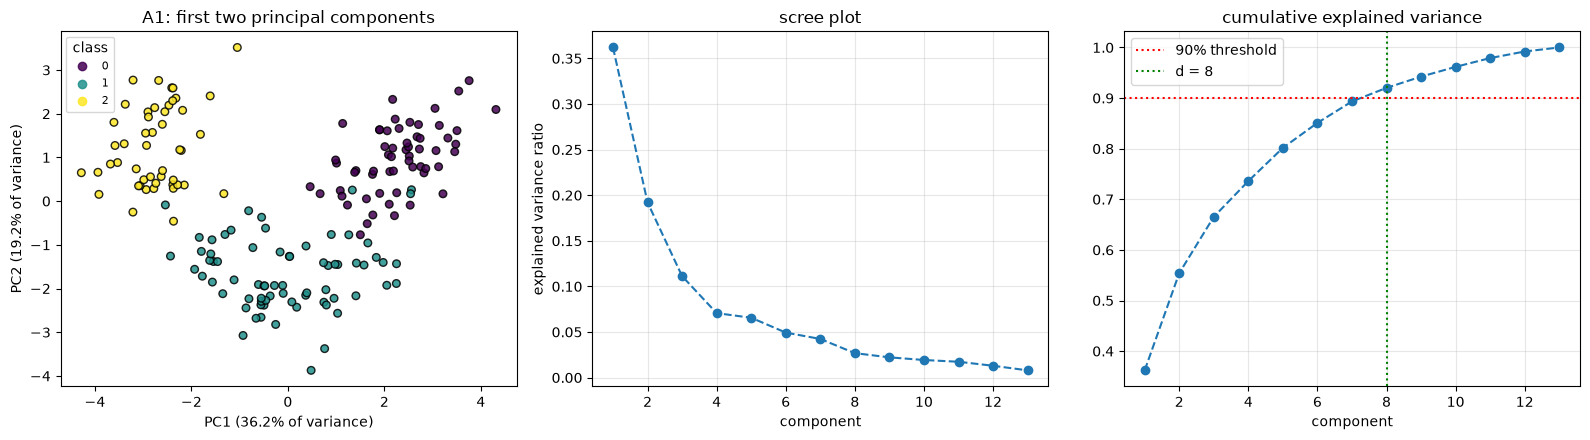

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sc = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="viridis", edgecolor="k", s=30, alpha=0.85)
axes[0].set_xlabel(f"PC1 ({evr[0]:.1%} of variance)")
axes[0].set_ylabel(f"PC2 ({evr[1]:.1%} of variance)")
axes[0].set_title(f"{SECTION}: first two principal components")
axes[0].legend(*sc.legend_elements(), title="class", loc="best", fontsize=8)

comps = np.arange(1, n + 1)
axes[1].plot(comps, evr, marker="o", linestyle="--")
axes[1].set_title("scree plot"); axes[1].set_xlabel("component"); axes[1].set_ylabel("explained variance ratio")
axes[1].grid(alpha=0.3)

axes[2].plot(comps, cum_evr, marker="o", linestyle="--")
axes[2].axhline(0.90, color="r", linestyle=":", label="90% threshold")
axes[2].axvline(n_components_90, color="g", linestyle=":", label=f"d = {n_components_90}")
axes[2].set_title("cumulative explained variance"); axes[2].set_xlabel("component"); axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Part 2 (autograded): reconstruction, and PCA *is* the SVD

**Why.** Suppose the lab keeps $d$ numbers per lot instead of 13. The director's next
question is the obvious one — *how much do we lose?* — and the lab's engineers, who already
use the SVD from last lecture for other work, will ask whether this is a new method or the
one they know. Both answers come from the same place.

**Reconstruction.** Keeping $d$ components is a *lossy compression*: $Y = XV'$ keeps $d$ numbers
per sample, and $\hat{X} = YV'^{T}$ maps them back to $n$ dimensions. The lecture's least-squares
picture says the part you lose is exactly the variance in the discarded directions, so

$$\frac{\|X - \hat{X}\|_F^2}{\|X\|_F^2} \;=\; 1 - \sum_{i=1}^{d}\frac{\lambda_i}{T}$$

for centered $X$. Verify it.


**Task 2a.** With $d$ = `n_components_90`:

- `X_recon` — the reconstruction of `X_scaled` from its first $d$ principal components, shape `(m, n)`.
  Use `pca_full.components_` (rows are the principal directions $\mathbf{v}_i^{T}$) and the
  full transform you already have, or `PCA(n_components=d)` with `inverse_transform` — either is fine.
- `recon_frac` — the fraction of the total sum of squares that is **lost**,
  $\|X_{\text{scaled}} - X_{\text{recon}}\|_F^2 \,/\, \|X_{\text{scaled}}\|_F^2$, as a `float`.

Then compare `recon_frac` with `1 - cum_evr[d - 1]`.


In [12]:
d = n_components_90
V_d = pca_full.components_[:d].T                  # (n, d): first d principal directions as columns
Y_d = pca_full.transform(X_scaled)[:, :d]         # (m, d): scores on those directions
X_recon = Y_d @ V_d.T + pca_full.mean_            # back to (m, n)
recon_frac = float(np.sum((X_scaled - X_recon) ** 2) / np.sum(X_scaled ** 2))

print(f"d = {d}: fraction of sum of squares lost = {recon_frac:.4f}")
print(f"1 - cumulative explained variance at d    = {1 - cum_evr[d - 1]:.4f}")

d = 8: fraction of sum of squares lost = 0.0798
1 - cumulative explained variance at d    = 0.0798


In [13]:
grader.check("q3")

q3 results: All test cases passed!

**PCA is the SVD.** Last lecture you decomposed a matrix as $X = U\Sigma V^{T}$. This lecture showed that
for *centered* $X$,

$$X^{T}X = V\Sigma^{2}V^{T},$$

so the principal directions are the columns of $V$, the covariance eigenvalues are
$\lambda_i = \sigma_i^{2}/(m-1)$, and the PCA **scores** are $Y = XV' = U'\Sigma'$ — the left singular
vectors scaled by the singular values. In practice nobody forms $S = \frac{1}{m-1}X^{T}X$; PCA is
computed by an SVD of $X$.


**Task 2b.** Verify this numerically **without calling `PCA`** — only `np.linalg.svd`:

- `U, s, Vt = np.linalg.svd(X_scaled, full_matrices=False)`
- `lambdas_svd` — the covariance eigenvalues recovered from `s` (length `n`);
- `Y_svd` — the 2-D PCA scores computed as $U'\Sigma'$ from the first two singular pairs, shape `(m, 2)`;
- `V2_svd` — the first two principal directions as columns, from `Vt`, shape `(n, 2)`.

`Y_svd` should match `X_pca` and `V2_svd` should match `pca_full.components_[:2].T` — up to a sign per
column, since $\mathbf{v}$ and $-\mathbf{v}$ are both unit eigenvectors.


In [14]:
U, s, Vt = np.linalg.svd(X_scaled, full_matrices=False)
lambdas_svd = s ** 2 / (m - 1)                    # covariance eigenvalues: sigma_i^2 / (m - 1)
Y_svd = U[:, :2] * s[:2]                          # U' Sigma': first two scores, (m, 2)
V2_svd = Vt[:2].T                                 # first two principal directions as columns, (n, 2)

print("eigenvalues from SVD:      ", np.round(lambdas_svd[:4], 4))
print("eigenvalues from sklearn:  ", np.round(pca_full.explained_variance_[:4], 4))
print("scores match up to sign:   ", np.allclose(np.abs(Y_svd), np.abs(X_pca)))
print("directions match up to sign:", np.allclose(np.abs(V2_svd), np.abs(pca_full.components_[:2].T)))

eigenvalues from SVD:       [4.7324 2.5111 1.4542 0.9242]
eigenvalues from sklearn:   [4.7324 2.5111 1.4542 0.9242]
scores match up to sign:    True
directions match up to sign: True


In [15]:
grader.check("q4")

q4 results: All test cases passed!

<!-- BEGIN QUESTION -->

**Discussion 2c (participation).** Two short answers; be ready to give them when staff visit.

1. The director asks: *"So how many numbers per lot? Where does your scree plot bend, and does
   that agree with your 90% rule?"* Which $d$ would you defend to her, and what does *"variance is
   not the same as usefulness"* add — does keeping 90% of the variance mean keeping 90% of what
   tells the cultivars apart? And be careful what you promise: is a principal component one of
   the 13 assays, or something else?
2. The lab's engineers ask why your scores matched theirs only *up to a sign* (the tests compared
   `np.abs(Y_svd)` with `np.abs(X_pca)`), and why `scikit-learn` computes PCA via the SVD of $X$
   rather than by eigendecomposing $S = \frac{1}{m-1}X^{T}X$ the way the lecture derived it.
   What do you tell them?


**1. How many numbers per lot?** The scree plot bends at about **3 components**. The first three explain 36%, 19% and 11% of the variance; after that each component adds only 4–7% and the curve flattens. The 90% rule asks for more: **d = 8** (92.0% retained, 8.0% of the sum of squares lost). So the two rules disagree, and the 90% cutoff is just a convention. Our recommendation depends on the purpose. If the goal is telling the cultivars apart, I would defend **d = 2–3**. In a quick check (logistic regression, 5-fold CV), PC1 alone gives 84% accuracy, PC1–2 give 96%, PC1–3 give 96%, d = 8 gives 98% and all 13 give 99%. If the goal is reproducing the full chemical profile of a lot, d = 8 is the honest number. *Variance is not usefulness*: PCA never saw the labels and ranks directions by spread, not by how well they separate cultivars. Keeping 90% of the variance does **not** mean keeping 90% of what distinguishes the cultivars. Here the useful signal happens to sit in the top components. It could just as easily have sat in a low-variance direction that PCA would throw away. Finally, a principal component is **not one of the 13 assays**. It is a weighted combination of all 13 (PC1 mixes flavanoids, total phenols, OD280/OD315, proanthocyanins and others). Computing even one PC score still requires running every assay, so PCA reduces the numbers we *store and analyse*, not the measurements the lab must *pay for*. Cutting assays would need a feature-selection method instead.

**2. Sign, and why the SVD.** If $\mathbf{v}$ is a unit eigenvector of $S$, so is $-\mathbf{v}$. Flipping $\mathbf{v}_i$ together with $\mathbf{u}_i$ leaves $U\Sigma V^T$ unchanged, so the sign of each component is arbitrary. Different routines (and `scikit-learn`'s `svd_flip` convention) can pick opposite signs, so the scores and directions agree only up to a sign per column. The geometry, the variances and the reconstruction are identical. `scikit-learn` takes the SVD of $X$ directly because forming $X^TX$ **squares the condition number**: small eigenvalues lose precision to floating-point round-off, and an SVD of $X$ avoids that. It is also cheaper and more flexible. It skips building the $n\times n$ matrix, gives the scores directly as $U\Sigma$, and supports truncated or randomized SVD when only the top $d$ components are needed.

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## Report out: what you would tell the lab

Write the two sentences you would put at the top of your memo to the lab: the
**recommendation**, and the **one caveat** they must hear. Use your own numbers
(`n_components_90`, `recon_frac`) — staff will stop at your table and ask you to defend
them. Then pair-share with another team.

Then the vendor's plot. The director wants one sentence she can repeat to importers about
the t-SNE plot in the sales deck, and there is no code to run here — you argue from the
lecture. Open the lecture's **perplexity × seed grid** (the slide *Perplexity and Seed
Change the Picture*) and its **three-blobs figure** (the slide *Cluster Sizes and Gaps Are
Not Preserved*), and add to your memo:

- **What the lab may claim.** In the grid, which feature of a t-SNE plot survives a change
  of seed and of perplexity, and so could support "wines from the same producer land
  together"? What would the vendor have to show you before you believed even that?
- **What the lab may not claim.** In the blobs figure the truth is known: two tight blobs
  10 apart and one five-times-wider blob 30 away. What does t-SNE do to the sizes and the
  gaps? Which parts of "producer A's wines are tightly clustered and far from producer B's,
  so they are chemically distinct" does that rule out?
- **Your rule.** One sentence the director can repeat to an importer: what a t-SNE plot of
  the lab's panel can be used to say, and what it cannot.


_Type your answer here, replacing this text._

<!-- END QUESTION -->

---

## Wrap-up: peer review

1. **Find another team** to pair with.
2. **Compare:** did you get the same `n_components_90` and `recon_frac`? Did you recommend the
   same $d$ to the lab?
3. **Argue:** if your memos disagree — on the recommendation, the caveat, or what the vendor's
   plot proves — work out which of you can point at evidence: your scree plot and
   reconstruction numbers, or the lecture's grid and blobs figures.
4. **Report back:** be ready to read your memo's two sentences, and your t-SNE rule, to the class.
